In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()  # Select Movie_Rating_Analysis_Workbook.xlsx
file_name = next(iter(uploaded))

# Read the cleaned dataset from the workbook
df = pd.read_excel(file_name, sheet_name="Cleaned Data")

# Prepare columns
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")
df["rating_year"] = pd.to_numeric(df["rating_year"], errors="coerce")
df = df.dropna(subset=["rating"])

print("Dataset shape:", df.shape)
print("\\nMissing values:\\n", df.isnull().sum())
print("\\nDuplicate rows:", df.duplicated().sum())
print("\\nUnique movies:", df["movieId"].nunique())
print("Unique users:", df["userId"].nunique())

Saving Movie_Rating_Analysis_Workbook.xlsx to Movie_Rating_Analysis_Workbook.xlsx
Dataset shape: (100836, 14)
\nMissing values:\n userId                  0
movieId                 0
title                   0
release_year           18
genres                  0
primary_genre           0
genre_count             0
rating                  0
rating_date             0
rating_year             0
movie_age_at_rating    18
release_decade         18
rating_category         0
liked                   0
dtype: int64
\nDuplicate rows: 0
\nUnique movies: 9724
Unique users: 610


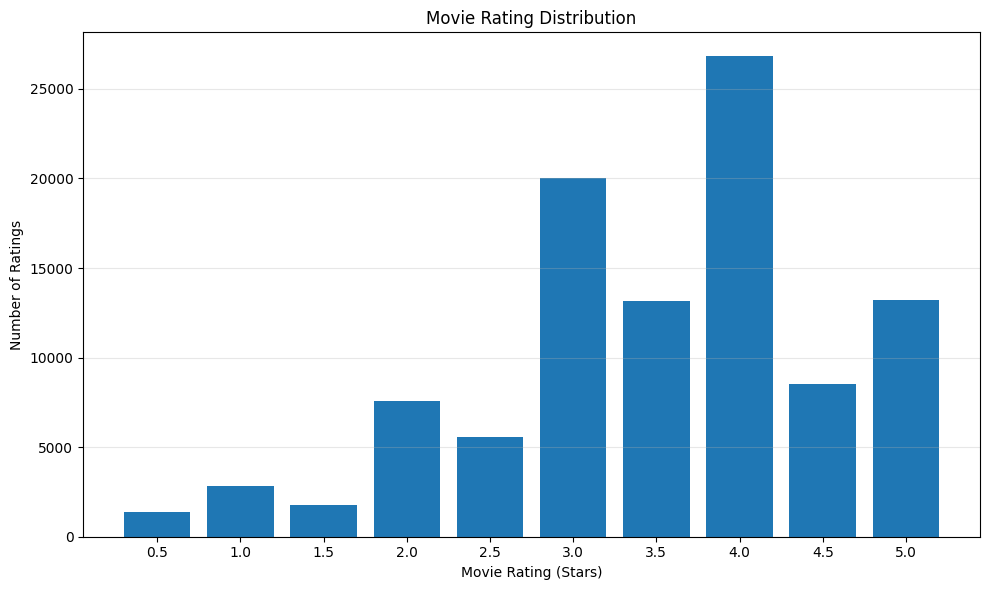

In [2]:
rating_counts = df["rating"].value_counts().sort_index()
plt.figure(figsize=(10, 6))
plt.bar(rating_counts.index.astype(str), rating_counts.values)
plt.title("Movie Rating Distribution")
plt.xlabel("Movie Rating (Stars)")
plt.ylabel("Number of Ratings")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

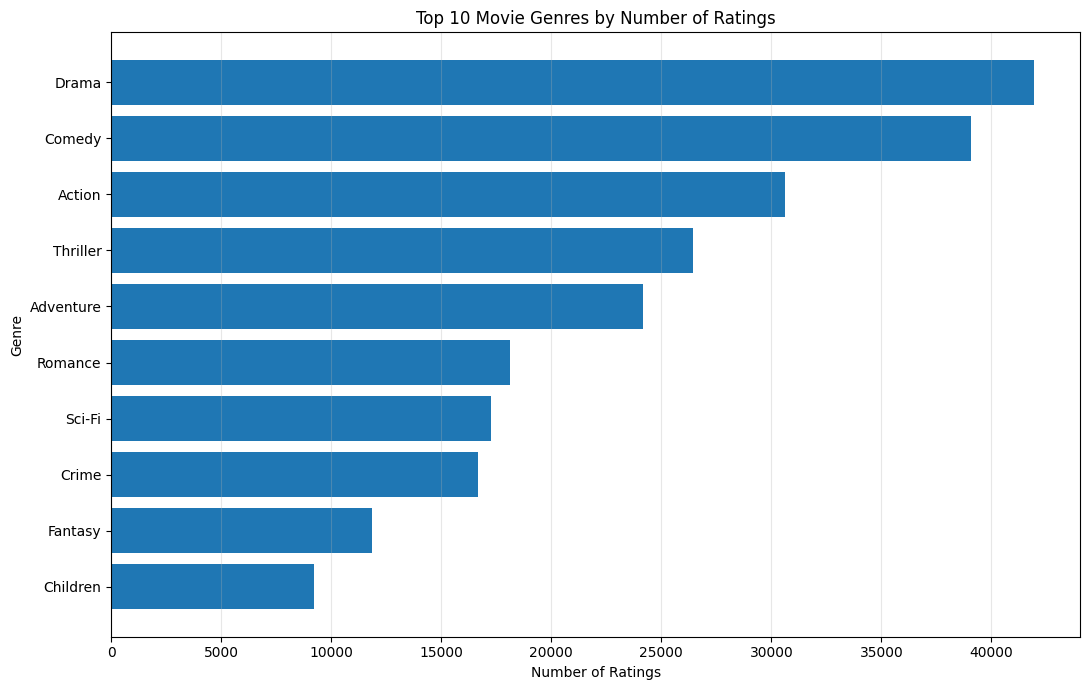

In [3]:
genre_df = df[["genres"]].dropna().copy()
genre_df["genres"] = genre_df["genres"].astype(str).str.split("|")
genre_counts = (
    genre_df.explode("genres")["genres"]
    .value_counts()
    .head(10)
    .sort_values()
)
plt.figure(figsize=(11, 7))
plt.barh(genre_counts.index, genre_counts.values)
plt.title("Top 10 Movie Genres by Number of Ratings")
plt.xlabel("Number of Ratings")
plt.ylabel("Genre")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


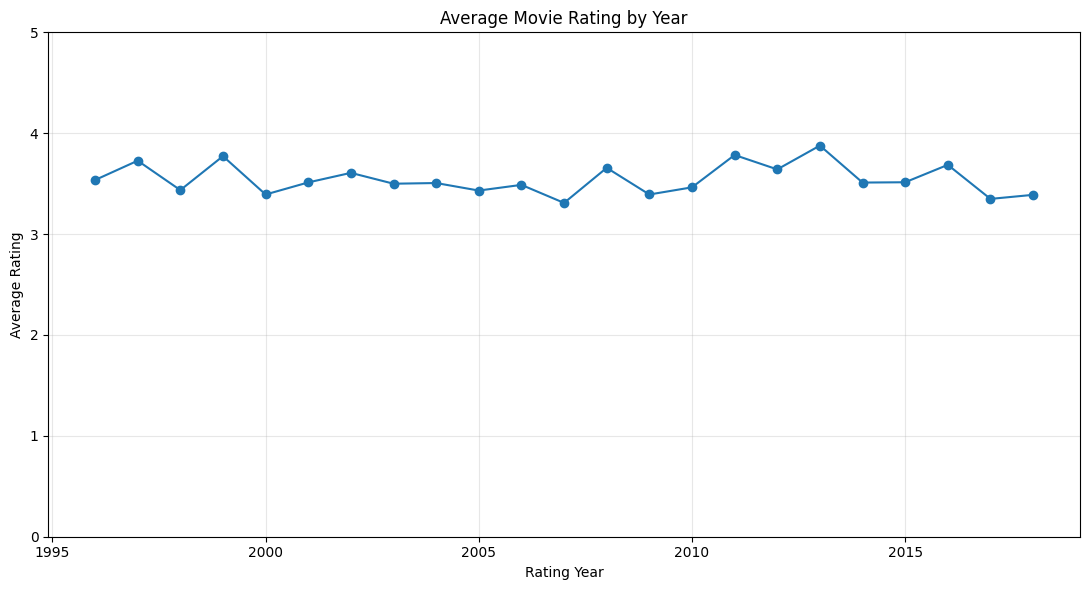

In [4]:
yearly = (
    df.dropna(subset=["rating_year"])
    .groupby("rating_year")["rating"]
    .mean()
)
plt.figure(figsize=(11, 6))
plt.plot(yearly.index.astype(int), yearly.values, marker="o")
plt.title("Average Movie Rating by Year")
plt.xlabel("Rating Year")
plt.ylabel("Average Rating")
plt.ylim(0, 5)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

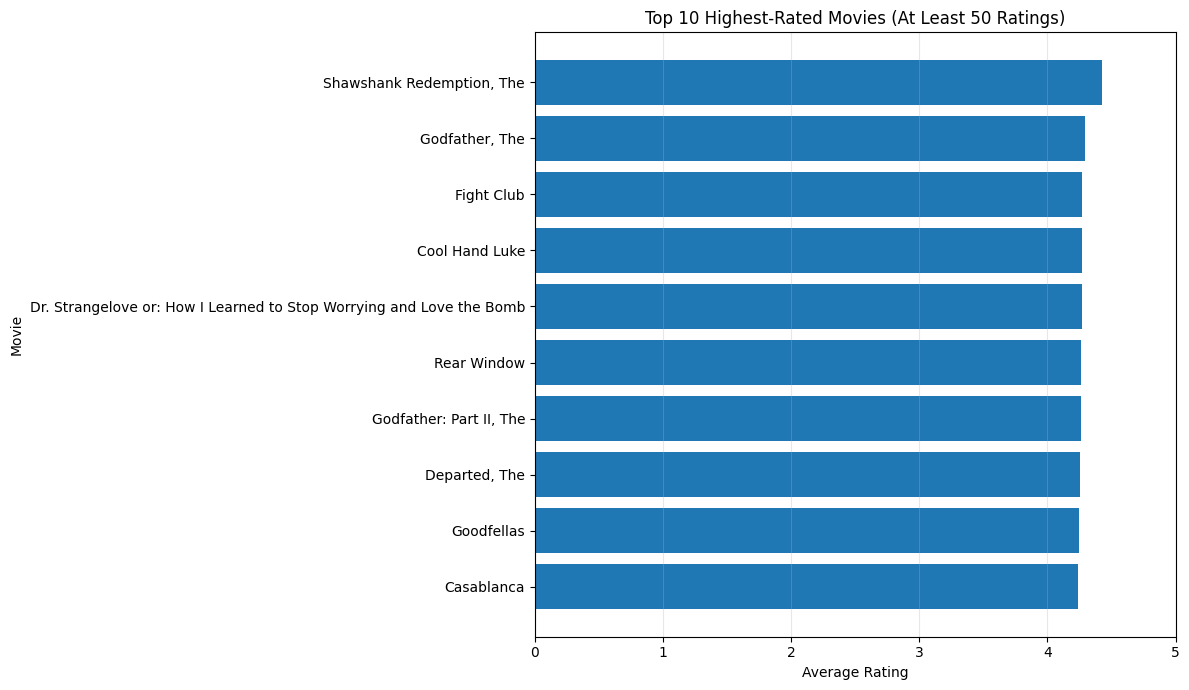

In [5]:
movie_stats = (
    df.groupby("title")
    .agg(avg_rating=("rating", "mean"),
         rating_count=("rating", "count"))
)
movie_stats = movie_stats[movie_stats["rating_count"] >= 50]
movie_stats = movie_stats.sort_values(
    ["avg_rating", "rating_count"], ascending=[False, False]
).head(10).sort_values("avg_rating")

plt.figure(figsize=(12, 7))
plt.barh(movie_stats.index, movie_stats["avg_rating"])
plt.title("Top 10 Highest-Rated Movies (At Least 50 Ratings)")
plt.xlabel("Average Rating")
plt.ylabel("Movie")
plt.xlim(0, 5)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
df.to_csv("movie_ratings_cleaned_output.csv", index=False)
print("\\nMovie rating analysis completed successfully.")

\nMovie rating analysis completed successfully.
